PHÂN CỤM KHÁCH HÀNG RFM BẰNG MINI-BATCH K-MEANS

Dữ liệu: customer_rfm.csv (xuất từ Fashion_DW, tại mốc 18/03/2025).
- Mục đích: phân nhóm khách hàng theo Recency, Frequency, Monetary, so sánh chất lượng cụm và đề xuất hỗ trợ quyết định.

1. Import thư viện và thiết lập

In [1]:
# Nếu thiếu thư viện, mở Terminal của Antigravity và chạy:
# python -m pip install pandas numpy scikit-learn matplotlib joblib ipykernel

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score

FOLDER = Path.cwd()
print('Thư mục hiện tại:', FOLDER)
print('Tìm thấy CSV:', (FOLDER / 'customer_rfm.csv').exists())

Thư mục hiện tại: e:\FashionRetail-DW\RFM_KMeans
Tìm thấy CSV: True


2. Đọc dữ liệu và khảo sát

In [2]:
df = pd.read_csv(FOLDER / 'customer_rfm.csv')
df.columns = df.columns.str.strip()
features = ['Recency', 'Frequency', 'Monetary']
print('Kích thước:', df.shape)
display(df.head())
display(df[features].describe())
print('Số dòng thiếu:', df[features + ['Customer_Key']].isna().any(axis=1).sum())
print('Số mã khách trùng:', df['Customer_Key'].duplicated().sum())

Kích thước: (1283707, 4)


,Customer_Key,Recency,Frequency,Monetary
0,1,150,5,335.4637
1,2,88,5,283.3814
2,3,166,5,216.0139
3,4,424,5,265.8814
4,5,11,5,223.0754


,Recency,Frequency,Monetary
count,1.283707e+06,1.283707e+06,1.283707e+06
mean,2.177806e+02,3.378707e+00,2.326482e+02
std,1.943072e+02,2.632995e+00,2.233639e+02
min,0.000000e+00,1.000000e+00,1.768900e+00
25%,8.000000e+01,1.000000e+00,7.500000e+01
50%,1.400000e+02,3.000000e+00,1.625000e+02
75%,3.450000e+02,4.000000e+00,3.169147e+02
max,8.070000e+02,3.500000e+01,3.274497e+03


Số dòng thiếu: 0
Số mã khách trùng: 0


3. Kiểm tra hợp lệ, biến đổi log và chuẩn hóa

In [3]:
assert set(['Customer_Key'] + features).issubset(df.columns)
assert df['Customer_Key'].notna().all()
assert not df['Customer_Key'].duplicated().any()
assert df[features].notna().all().all()
assert (df['Recency'] >= 0).all()
assert (df['Frequency'] >= 1).all()
assert (df['Monetary'] >= 0).all()

X_log = np.log1p(df[features].astype('float64'))
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)
print('Kích thước ma trận:', X_scaled.shape)
print('Trung bình sau chuẩn hóa:', X_scaled.mean(axis=0).round(4))
print('Độ lệch chuẩn:', X_scaled.std(axis=0).round(4))

Kích thước ma trận: (1283707, 3)
Trung bình sau chuẩn hóa: [-0.  0. -0.]
Độ lệch chuẩn: [1. 1. 1.]


4. Thử nhiều số cụm K và đánh giá Silhouette

In [4]:
rng = np.random.default_rng(42)
train_idx = rng.choice(len(df), size=min(100_000, len(df)), replace=False)
X_train = X_scaled[train_idx]
rows = []
for k in range(3, 7):
    model = MiniBatchKMeans(n_clusters=k, random_state=42,
                            batch_size=4096, n_init=10, max_iter=150)
    labels = model.fit_predict(X_train)
    score = silhouette_score(X_train, labels,
                             sample_size=min(3000, len(X_train)),
                             random_state=42)
    rows.append({'K': k, 'Silhouette': score, 'Inertia': model.inertia_})
    print(f'K={k}: Silhouette={score:.4f}, Inertia={model.inertia_:.1f}')
result_df = pd.DataFrame(rows)
display(result_df)
result_df.to_csv(FOLDER / 'k_evaluation.csv', index=False)

K=3: Silhouette=0.3805, Inertia=122554.2
K=4: Silhouette=0.2629, Inertia=104969.9
K=5: Silhouette=0.3276, Inertia=80692.8
K=6: Silhouette=0.2867, Inertia=71482.2


,K,Silhouette,Inertia
0,3,0.380512,122554.163633
1,4,0.262942,104969.931129
2,5,0.327637,80692.783805
3,6,0.286679,71482.237404


5. Biểu đồ so sánh K

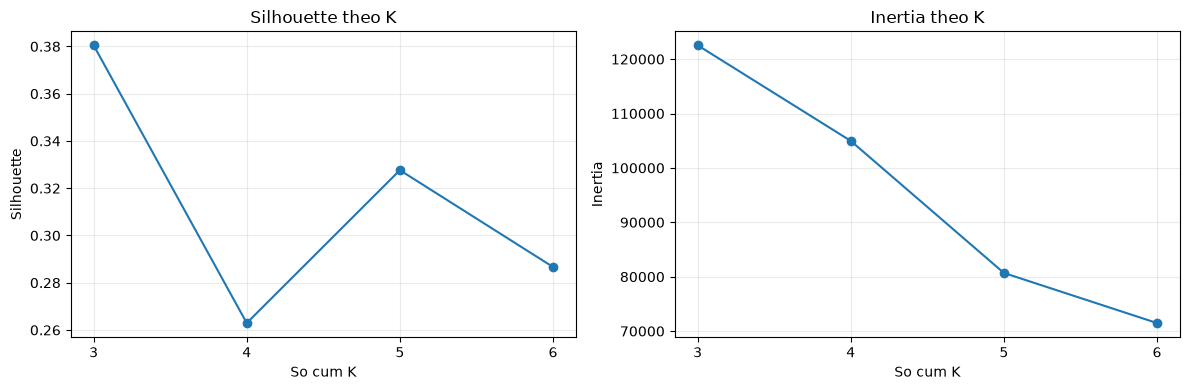

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(result_df['K'], result_df['Silhouette'], 'o-')
axes[0].set(title='Silhouette theo K', xlabel='So cum K', ylabel='Silhouette')
axes[1].plot(result_df['K'], result_df['Inertia'], 'o-')
axes[1].set(title='Inertia theo K', xlabel='So cum K', ylabel='Inertia')
for ax in axes:
    ax.set_xticks(result_df['K'])
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(FOLDER / 'k_evaluation.png', dpi=180)
plt.show()

6. Huấn luyện mô hình cuối cùng trên toàn bộ RFM

In [7]:
best_k = int(result_df.loc[result_df['Silhouette'].idxmax(), 'K'])
print('K đề xuất theo Silhouette:', best_k)
final_model = MiniBatchKMeans(n_clusters=best_k, random_state=42,
                              batch_size=4096, n_init=10, max_iter=200)
df['Cluster'] = final_model.fit_predict(X_scaled)
print('Số cụm thực tế:', df['Cluster'].nunique())
print('Tổng khách được gắn cụm:', df['Cluster'].notna().sum())

K đề xuất theo Silhouette: 3
Số cụm thực tế: 3
Tổng khách được gắn cụm: 1283707


7. Phân tích đặc điểm của các cụm

In [8]:
summary = df.groupby('Cluster').agg(
    Customers=('Customer_Key', 'size'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean'),
    Median_Recency=('Recency', 'median'),
    Median_Frequency=('Frequency', 'median'),
    Median_Monetary=('Monetary', 'median'),
    Total_Revenue=('Monetary', 'sum')
).reset_index()
summary['Customer_Share_Pct'] = summary['Customers'] / len(df) * 100
summary['Revenue_Share_Pct'] = summary['Total_Revenue'] / summary['Total_Revenue'].sum() * 100
display(summary.round(2))
summary.to_csv(FOLDER / 'cluster_summary.csv', index=False)
assert summary['Customers'].sum() == len(df)
assert abs(summary['Revenue_Share_Pct'].sum()-100) < 0.001

,Cluster,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Recency,Median_Frequency,Median_Monetary,Total_Revenue,Customer_Share_Pct,Revenue_Share_Pct
0,0,538924,186.47,3.10,218.28,142.0,3.0,190.00,1.176354e+08,41.98,39.39
1,1,436273,364.30,1.28,62.69,365.0,1.0,53.50,2.735071e+07,33.99,9.16
2,2,308510,65.28,6.84,498.09,70.0,6.0,443.19,1.536660e+08,24.03,51.45


8. Trực quan hóa kết quả phân khúc

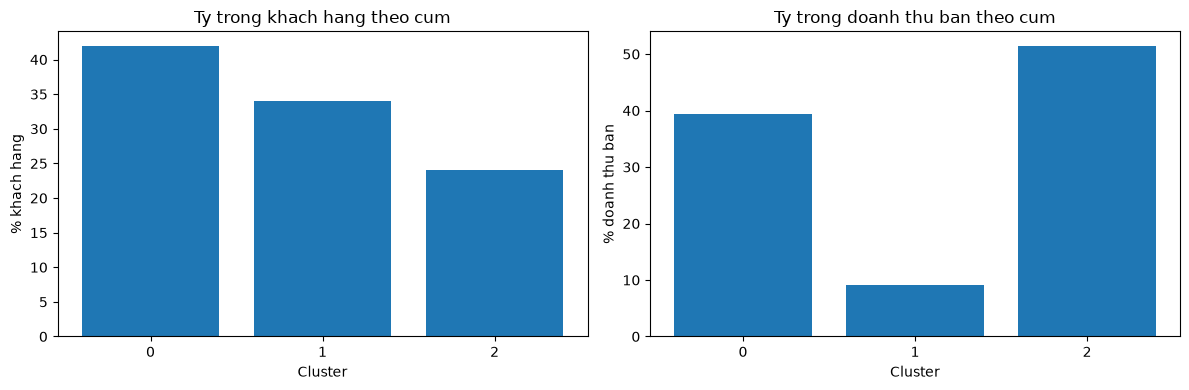

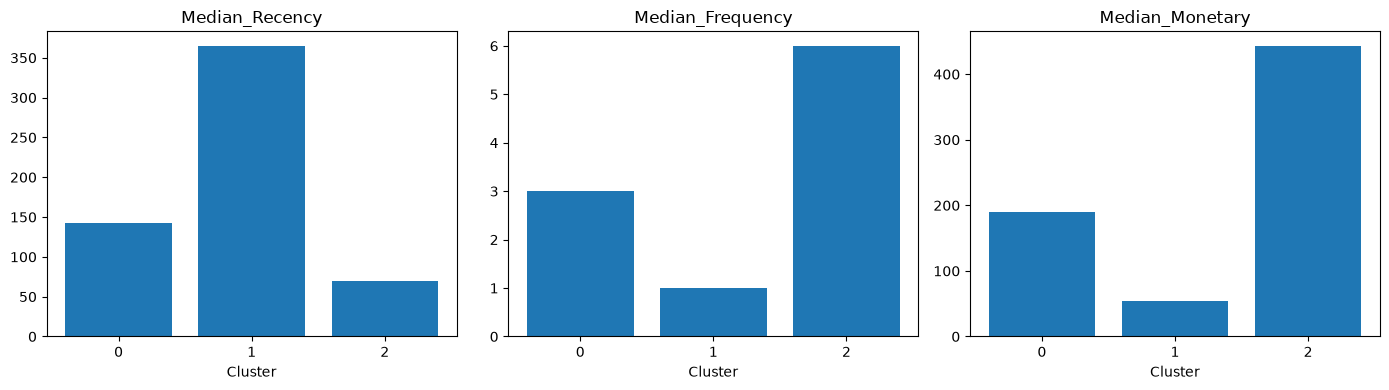

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(summary['Cluster'].astype(str), summary['Customer_Share_Pct'])
axes[0].set(title='Ty trong khach hang theo cum', xlabel='Cluster', ylabel='% khach hang')
axes[1].bar(summary['Cluster'].astype(str), summary['Revenue_Share_Pct'])
axes[1].set(title='Ty trong doanh thu ban theo cum', xlabel='Cluster', ylabel='% doanh thu ban')
plt.tight_layout()
plt.savefig(FOLDER / 'cluster_shares.png', dpi=180)
plt.show()

# Biểu đồ mô tả trung vị RFM từng cụm
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ['Median_Recency','Median_Frequency','Median_Monetary']):
    ax.bar(summary['Cluster'].astype(str), summary[col])
    ax.set(title=col, xlabel='Cluster')
plt.tight_layout()
plt.savefig(FOLDER / 'cluster_rfm_medians.png', dpi=180)
plt.show()

9. Lưu dữ liệu phân cụm và mô hình

In [11]:
df.to_csv(FOLDER / 'customer_segments.csv', index=False)
joblib.dump({'model': final_model, 'scaler': scaler, 'features': features,
             'log_transform': 'np.log1p', 'analysis_date': '2025-03-18'},
            FOLDER / 'rfm_kmeans_model.joblib')
print('Đã lưu customer_segments.csv, cluster_summary.csv, k_evaluation.csv, các PNG và model.')

Đã lưu customer_segments.csv, cluster_summary.csv, k_evaluation.csv, các PNG và model.


10. Nhận xét và ý nghĩa hỗ trợ ra quyết định — cần điền sau khi chạy

Đánh giá thuật toán: Mô tả K được lựa chọn theo Silhouette, so sánh với các K khác; nêu rõ giới hạn của việc lấy mẫu và sự phụ thuộc vào biến đổi/chuẩn hóa.

Đánh giá nghiệp vụ: Dựa vào trung vị RFM của mỗi cụm để đặt tên phù hợp (không tự gán nhãn trước). So sánh tỷ trọng khách hàng và doanh thu bán. Monetary được xây dựng từ giao dịch Sale nên tổng này là doanh thu bán chưa trừ hàng Return, không phải doanh thu thuần.

Quyết định đề xuất: Xác định cụm đáng ưu tiên chăm sóc, cụm cần tái kích hoạt, cụm có thể thử chiến dịch chi phí thấp; đây là đề xuất thử nghiệm, không phải hiệu quả chiến dịch đã được chứng minh.

Hạn chế: Dữ liệu đến 18/03/2025; không khẳng định đây là dự báo rời bỏ hoặc doanh thu tương lai; cần kiểm thử các chính sách sau khi triển khai.

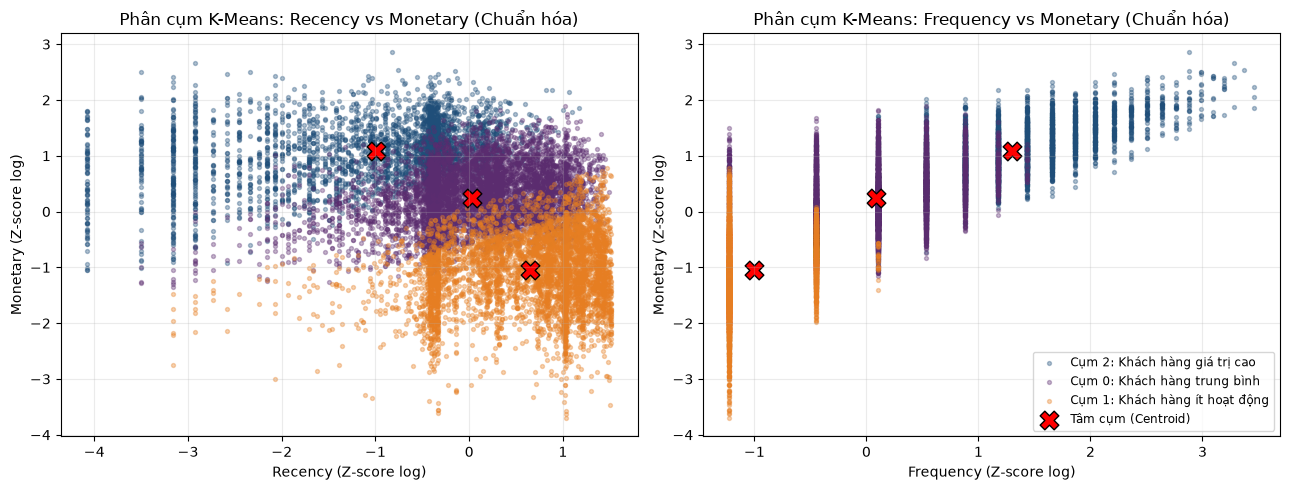

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from pathlib import Path

FOLDER = Path.cwd() if (Path.cwd() / 'customer_segments.csv').exists() else Path.cwd() / 'RFM_KMeans'

# Đọc trực tiếp dữ liệu phân cụm và mô hình đã lưu
df = pd.read_csv(FOLDER / 'customer_segments.csv')
bundle = joblib.load(FOLDER / 'rfm_kmeans_model.joblib')

final_model = bundle['model']
scaler = bundle['scaler']
features = bundle['features']

# Biến đổi lại theo đúng scaler đã huấn luyện
X_log = np.log1p(df[features].astype('float64'))
X_scaled = scaler.transform(X_log)

# Lấy mẫu ngẫu nhiên 15.000 điểm để vẽ Scatter Plot rõ ràng
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(df), size=15_000, replace=False)
X_vis = X_scaled[sample_idx]
y_vis = df['Cluster'].values[sample_idx]
centers = final_model.cluster_centers_

segment_labels = {
    0: 'Cụm 0: Khách hàng trung bình',
    1: 'Cụm 1: Khách hàng ít hoạt động',
    2: 'Cụm 2: Khách hàng giá trị cao'
}
colors = {0: '#5B2C6F', 1: '#E67E22', 2: '#1F4E79'}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Biểu đồ 1: Recency vs Monetary (đã chuẩn hóa)
for c in [2, 0, 1]:
    mask = (y_vis == c)
    axes[0].scatter(X_vis[mask, 0], X_vis[mask, 2], s=8, alpha=0.35, color=colors[c], label=segment_labels[c])
axes[0].scatter(centers[:, 0], centers[:, 2], s=180, c='red', marker='X', edgecolor='black', label='Tâm cụm (Centroid)')
axes[0].set(title='Phân cụm K-Means: Recency vs Monetary (Chuẩn hóa)', xlabel='Recency (Z-score log)', ylabel='Monetary (Z-score log)')
axes[0].grid(alpha=0.25)

# Biểu đồ 2: Frequency vs Monetary (đã chuẩn hóa)
for c in [2, 0, 1]:
    mask = (y_vis == c)
    axes[1].scatter(X_vis[mask, 1], X_vis[mask, 2], s=8, alpha=0.35, color=colors[c], label=segment_labels[c])
axes[1].scatter(centers[:, 1], centers[:, 2], s=180, c='red', marker='X', edgecolor='black', label='Tâm cụm (Centroid)')
axes[1].set(title='Phân cụm K-Means: Frequency vs Monetary (Chuẩn hóa)', xlabel='Frequency (Z-score log)', ylabel='Monetary (Z-score log)')
axes[1].grid(alpha=0.25)

axes[1].legend(loc='lower right', fontsize=8.5, frameon=True)
plt.tight_layout()
plt.savefig(FOLDER / 'cluster_scatter_kmeans.png', dpi=180)
plt.show()